In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ecommerce_dataset.csv")

In [53]:
df.head()

,order_id,order_date,region,category,product,quantity,unit_price,sales_channel,revenue,month
0,ORD1001,2025-01-03,North,Electronics,Wireless Mouse,2.0,25.0,Online,50.0,2025-01
1,ORD1002,2025-01-05,South,Home,Desk Lamp,1.0,32.5,Store,32.5,2025-01
2,ORD1003,2025-01-08,East,Fashion,Cotton T-Shirt,3.0,15.0,Online,45.0,2025-01
3,ORD1004,2025-01-11,West,Electronics,Usb-C Hub,1.0,48.0,Online,48.0,2025-01
4,ORD1005,2025-01-14,North,Home,Water Bottle,4.0,12.0,Store,48.0,2025-01


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       61 non-null     str    
 1   order_date     61 non-null     str    
 2   region         60 non-null     str    
 3   category       61 non-null     str    
 4   product        61 non-null     str    
 5   quantity       60 non-null     float64
 6   unit_price     60 non-null     float64
 7   sales_channel  61 non-null     str    
dtypes: float64(2), str(6)
memory usage: 3.9 KB


In [10]:
df.describe()

,quantity,unit_price
count,60.000000,60.000000
mean,2.066667,37.941667
std,1.313124,44.941307
min,-2.000000,-185.000000
25%,1.000000,18.000000
50%,2.000000,35.250000
75%,3.000000,48.000000
max,6.000000,185.000000


In [12]:
df.shape

(61, 8)

In [14]:
df.duplicated().sum()

np.int64(1)

In [17]:
df = df.drop_duplicates()
df

,order_id,order_date,region,category,product,quantity,unit_price,sales_channel
0,ORD1001,2025-01-03,North,Electronics,Wireless Mouse,2.0,25.0,Online
1,ORD1002,2025-01-05,South,Home,Desk Lamp,1.0,32.5,Store
2,ORD1003,2025-01-08,East,Fashion,Cotton T-Shirt,3.0,15.0,Online
3,ORD1004,2025-01-11,West,Electronics,USB-C Hub,1.0,48.0,Online
4,ORD1005,2025-01-14,North,Home,Water Bottle,4.0,12.0,Store
5,ORD1006,2025-01-17,South,Fashion,Sneakers,1.0,65.0,Online
6,ORD1007,2025-01-20,NaN,Electronics,Bluetooth Speaker,2.0,39.0,Store
7,ORD1008,2025-01-23,West,Home,Storage Box,3.0,18.0,Online
8,ORD1009,2025-01-26,North,Fashion,Hoodie,2.0,42.0,Online
9,ORD1010,2025-01-29,South,Electronics,Keyboard,1.0,55.0,Store


In [19]:
df["region"] = df["region"].str.strip().str.title()
df["category"] = df["category"].str.strip().str.title()
df["product"] = df["product"].str.strip().str.title()
df["sales_channel"] = df["sales_channel"].str.strip().str.title()

In [22]:
df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"], errors="coerce"
)

df["unit_price"] = pd.to_numeric(
    df["unit_price"], errors="coerce"
)

df.head()

,order_id,order_date,region,category,product,quantity,unit_price,sales_channel
0,ORD1001,2025-01-03,North,Electronics,Wireless Mouse,2.0,25.0,Online
1,ORD1002,2025-01-05,South,Home,Desk Lamp,1.0,32.5,Store
2,ORD1003,2025-01-08,East,Fashion,Cotton T-Shirt,3.0,15.0,Online
3,ORD1004,2025-01-11,West,Electronics,Usb-C Hub,1.0,48.0,Online
4,ORD1005,2025-01-14,North,Home,Water Bottle,4.0,12.0,Store


In [24]:
df.loc[df["quantity"] < 0, "quantity"] = np.nan
df.loc[df["unit_price"] < 0, "unit_price"] = np.nan

df.loc[df["quantity"] == 0, "quantity"] = np.nan

df.head(3)

,order_id,order_date,region,category,product,quantity,unit_price,sales_channel
0,ORD1001,2025-01-03,North,Electronics,Wireless Mouse,2.0,25.0,Online
1,ORD1002,2025-01-05,South,Home,Desk Lamp,1.0,32.5,Store
2,ORD1003,2025-01-08,East,Fashion,Cotton T-Shirt,3.0,15.0,Online


In [27]:
df["region"] = df["region"].fillna("Unknown")

df["quantity"] = df["quantity"].fillna(
    df["quantity"].median()
)

df["unit_price"] = df["unit_price"].fillna(
    df["unit_price"].median()
)

df = df.dropna(subset=["order_date"])

In [29]:
df.isna().sum()

order_id         0
order_date       0
region           0
category         0
product          0
quantity         0
unit_price       0
sales_channel    0
dtype: int64

In [31]:
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.DataFrame'>
Index: 59 entries, 0 to 59
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       59 non-null     str           
 1   order_date     59 non-null     datetime64[us]
 2   region         59 non-null     str           
 3   category       59 non-null     str           
 4   product        59 non-null     str           
 5   quantity       59 non-null     float64       
 6   unit_price     59 non-null     float64       
 7   sales_channel  59 non-null     str           
dtypes: datetime64[us](1), float64(2), str(5)
memory usage: 4.1 KB


np.int64(0)

In [33]:
df["revenue"] = df["quantity"] * df["unit_price"]

In [35]:
df["month"] = df["order_date"].dt.to_period("M").astype(str)

In [37]:
df[[
    "order_id",
    "order_date",
    "month",
    "region",
    "product",
    "quantity",
    "unit_price",
    "revenue"
]].head(10)

,order_id,order_date,month,region,product,quantity,unit_price,revenue
0,ORD1001,2025-01-03,2025-01,North,Wireless Mouse,2.0,25.0,50.0
1,ORD1002,2025-01-05,2025-01,South,Desk Lamp,1.0,32.5,32.5
2,ORD1003,2025-01-08,2025-01,East,Cotton T-Shirt,3.0,15.0,45.0
3,ORD1004,2025-01-11,2025-01,West,Usb-C Hub,1.0,48.0,48.0
4,ORD1005,2025-01-14,2025-01,North,Water Bottle,4.0,12.0,48.0
5,ORD1006,2025-01-17,2025-01,South,Sneakers,1.0,65.0,65.0
6,ORD1007,2025-01-20,2025-01,Unknown,Bluetooth Speaker,2.0,39.0,78.0
7,ORD1008,2025-01-23,2025-01,West,Storage Box,3.0,18.0,54.0
8,ORD1009,2025-01-26,2025-01,North,Hoodie,2.0,42.0,84.0
9,ORD1010,2025-01-29,2025-01,South,Keyboard,1.0,55.0,55.0


In [39]:
monthly_revenue = (
    df.groupby("month")["revenue"]
      .sum()
      .reset_index()
      .sort_values("month")
)

monthly_revenue

,month,revenue
0,2025-01,559.5
1,2025-02,744.0
2,2025-03,624.0
3,2025-04,923.0
4,2025-05,666.5
5,2025-06,580.0


In [41]:
region_revenue = (
    df.groupby("region")["revenue"]
      .sum()
      .reset_index()
      .sort_values("revenue", ascending=False)
)

region_revenue

,region,revenue
2,South,1098.5
0,East,1077.0
1,North,935.0
4,West,908.5
3,Unknown,78.0


In [43]:
product_revenue = (
    df.groupby("product")["revenue"]
      .sum()
      .reset_index()
      .sort_values("revenue", ascending=False)
)

product_revenue

,product,revenue
11,Monitor,408.0
8,Jacket,356.0
18,Webcam,288.0
14,Sneakers,271.0
9,Jeans,266.0
16,Usb-C Hub,240.0
0,Bed Sheet,225.0
10,Keyboard,220.0
7,Hoodie,210.0
13,Power Bank,203.0


In [45]:
monthly_region_product = (
    df.groupby(["month", "region", "product"], as_index=False)
      .agg(
          total_quantity=("quantity", "sum"),
          total_revenue=("revenue", "sum"),
          average_revenue=("revenue", "mean")
      )
)

monthly_region_product.head(10)

,month,region,product,total_quantity,total_revenue,average_revenue
0,2025-01,East,Cotton T-Shirt,3.0,45.0,45.0
1,2025-01,North,Hoodie,2.0,84.0,84.0
2,2025-01,North,Water Bottle,4.0,48.0,48.0
3,2025-01,North,Wireless Mouse,2.0,50.0,50.0
4,2025-01,South,Desk Lamp,1.0,32.5,32.5
5,2025-01,South,Keyboard,1.0,55.0,55.0
6,2025-01,South,Sneakers,1.0,65.0,65.0
7,2025-01,Unknown,Bluetooth Speaker,2.0,78.0,78.0
8,2025-01,West,Storage Box,3.0,54.0,54.0
9,2025-01,West,Usb-C Hub,1.0,48.0,48.0


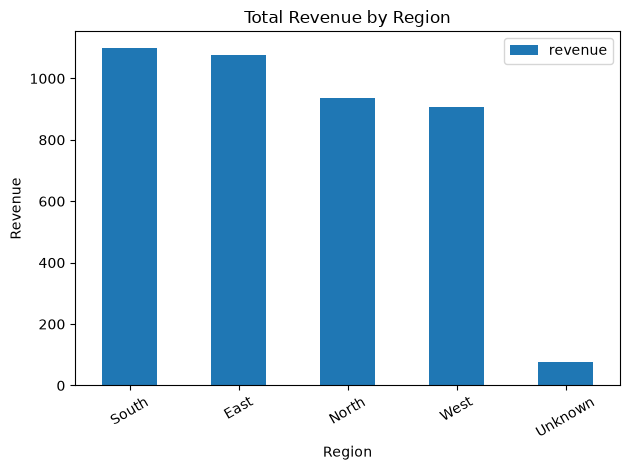

In [47]:
region_revenue.plot(
    x="region",
    y="revenue",
    kind="bar",
    title="Total Revenue by Region"
)

plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

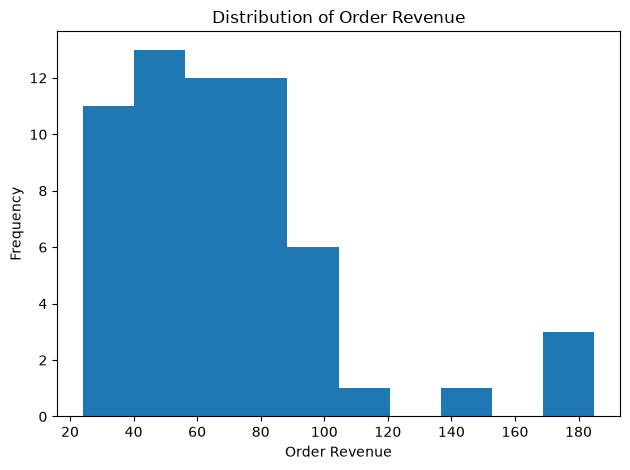

In [51]:
df["revenue"].plot(
    kind="hist",
    bins=10,
    title="Distribution of Order Revenue"
)

plt.xlabel("Order Revenue")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

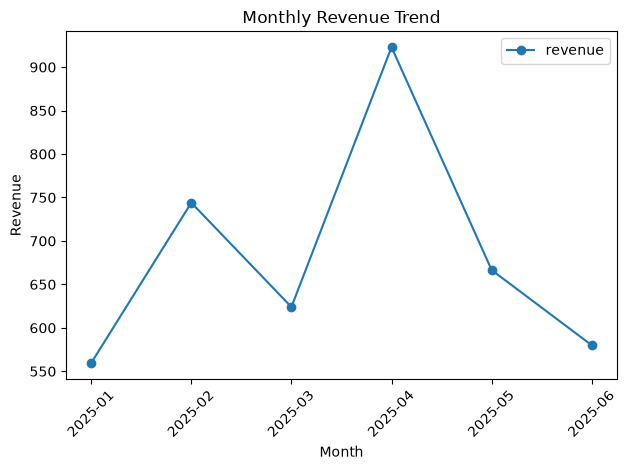

In [54]:
monthly_revenue.plot(
    x="month",
    y="revenue",
    kind="line",
    marker="o",
    title="Monthly Revenue Trend"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

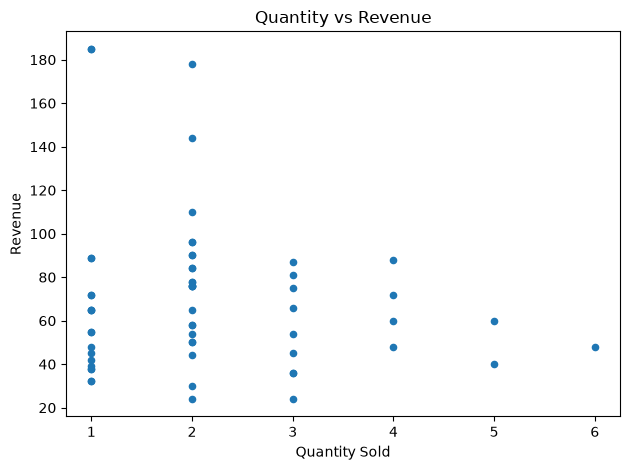

In [55]:
df.plot(
    x="quantity",
    y="revenue",
    kind="scatter",
    title="Quantity vs Revenue"
)

plt.xlabel("Quantity Sold")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()